In [1]:
# STEP 1: Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# STEP 2: Load Dataset

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

df = pd.read_csv(url)

print("Titanic Dataset Loaded Successfully!")

display(df.head())

Titanic Dataset Loaded Successfully!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# STEP 3: Dataset Information

print("Number of Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Number of Rows and Columns:
(891, 12)

Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived        

In [5]:
# STEP 4: Summary Statistics

print("Complete Statistical Summary")

display(df.describe())

print("\nMean:")
display(df.mean(numeric_only=True))

print("\nMedian:")
display(df.median(numeric_only=True))

print("\nStandard Deviation:")
display(df.std(numeric_only=True))

Complete Statistical Summary


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Mean:


,0
PassengerId,446.000000
Survived,0.383838
Pclass,2.308642
Age,29.699118
SibSp,0.523008
Parch,0.381594
Fare,32.204208



Median:


,0
PassengerId,446.0000
Survived,0.0000
Pclass,3.0000
Age,28.0000
SibSp,0.0000
Parch,0.0000
Fare,14.4542



Standard Deviation:


,0
PassengerId,257.353842
Survived,0.486592
Pclass,0.836071
Age,14.526497
SibSp,1.102743
Parch,0.806057
Fare,49.693429


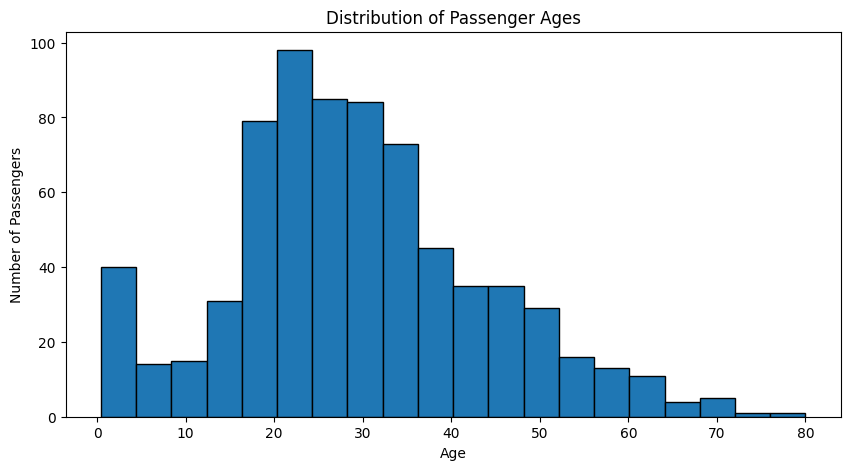

In [6]:
# STEP 5: Histogram

plt.figure(figsize=(10, 5))

plt.hist(
    df["Age"].dropna(),
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Passenger Ages")

plt.xlabel("Age")

plt.ylabel("Number of Passengers")

plt.show()

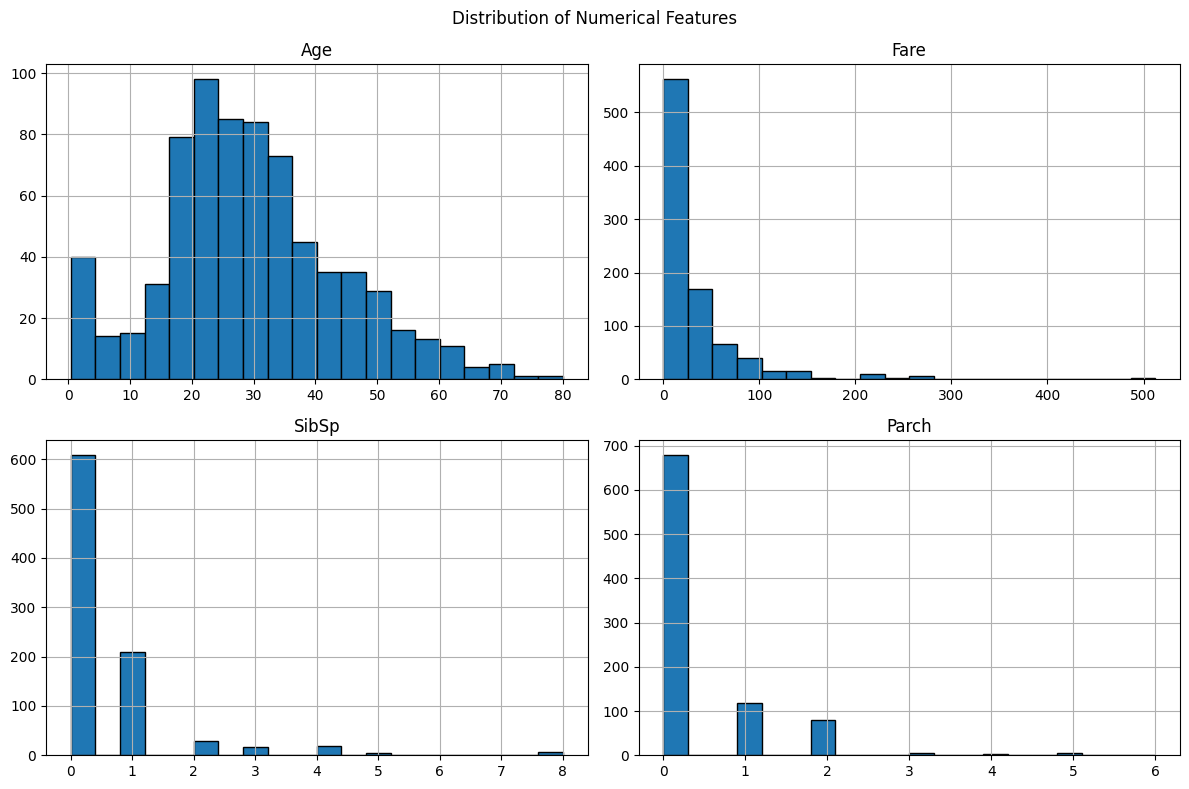

In [7]:
# Multiple Histograms

df[["Age", "Fare", "SibSp", "Parch"]].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features")

plt.tight_layout()

plt.show()

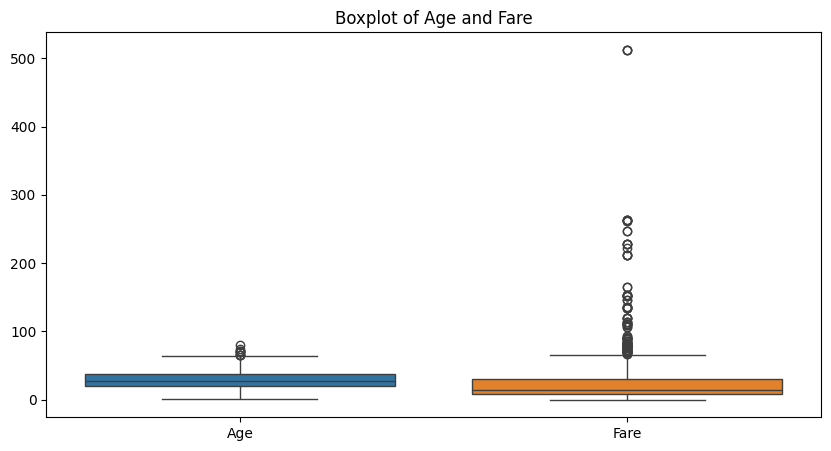

In [8]:
# STEP 6: Boxplot

plt.figure(figsize=(10, 5))

sns.boxplot(data=df[["Age", "Fare"]])

plt.title("Boxplot of Age and Fare")

plt.show()

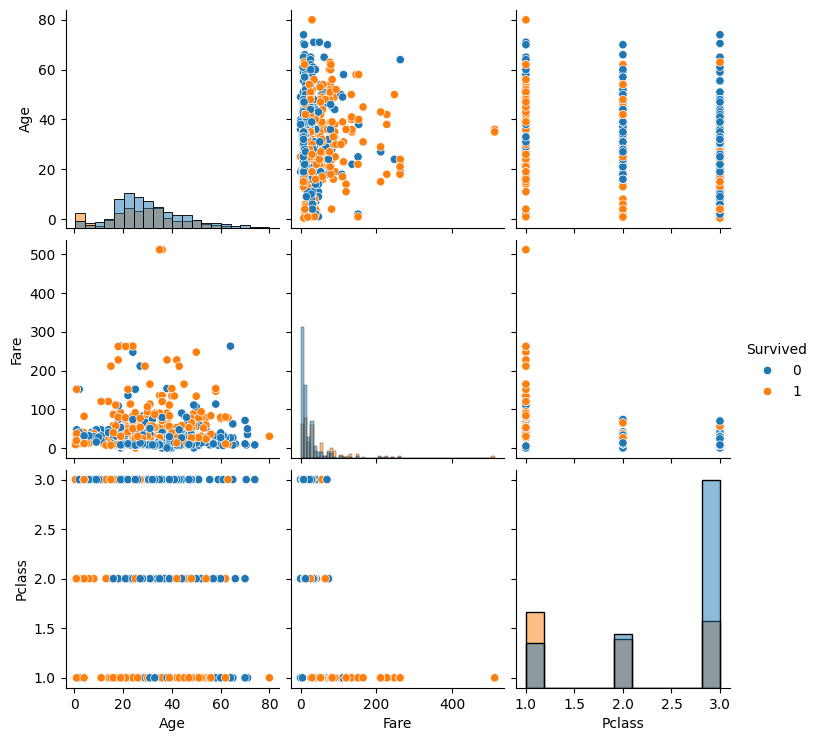

In [9]:
# STEP 7: Pairplot

sns.pairplot(
    df[["Survived", "Age", "Fare", "Pclass"]],
    hue="Survived",
    diag_kind="hist"
)

plt.show()

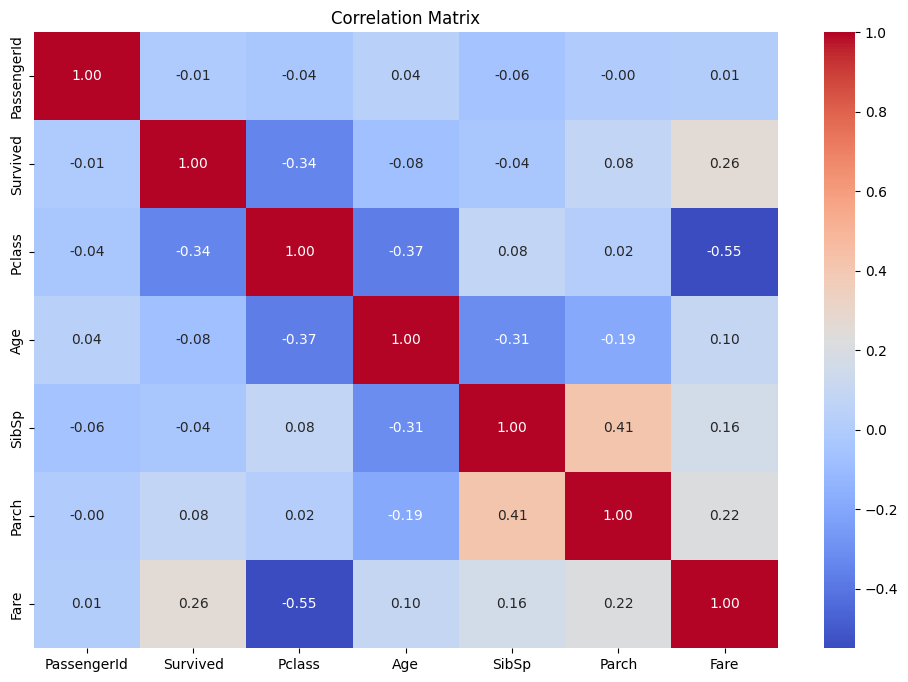

In [10]:
# STEP 8: Correlation Matrix

correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

Survival Rate by Gender:
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


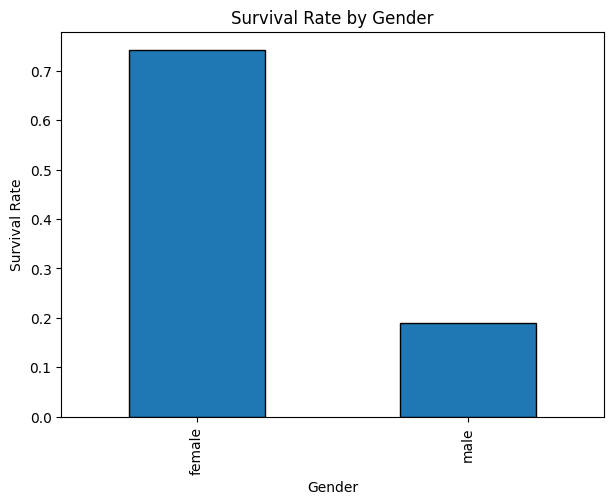

In [11]:
# STEP 9: Survival by Gender

gender_survival = df.groupby("Sex")["Survived"].mean()

print("Survival Rate by Gender:")

print(gender_survival)

gender_survival.plot(
    kind="bar",
    figsize=(7, 5),
    edgecolor="black"
)

plt.title("Survival Rate by Gender")

plt.xlabel("Gender")

plt.ylabel("Survival Rate")

plt.show()

Survival Rate by Passenger Class:
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


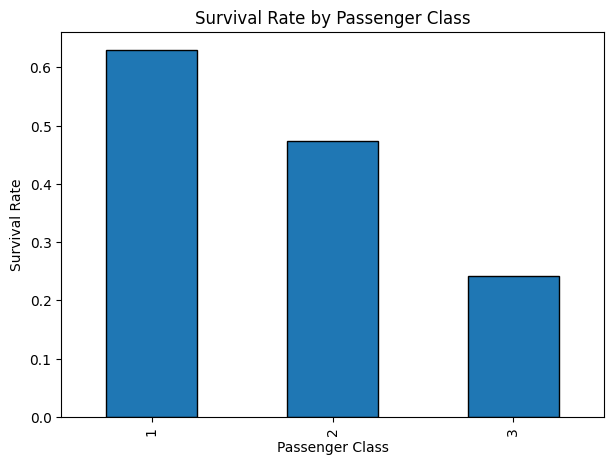

In [12]:
# Survival by Passenger Class

class_survival = df.groupby("Pclass")["Survived"].mean()

print("Survival Rate by Passenger Class:")

print(class_survival)

class_survival.plot(
    kind="bar",
    figsize=(7, 5),
    edgecolor="black"
)

plt.title("Survival Rate by Passenger Class")

plt.xlabel("Passenger Class")

plt.ylabel("Survival Rate")

plt.show()

In [13]:
# STEP 10: Interactive Visualization using Plotly

fig = px.scatter(
    df,
    x="Age",
    y="Fare",
    color="Survived",
    title="Age vs Fare - Titanic Dataset",
    labels={
        "Age": "Passenger Age",
        "Fare": "Ticket Fare",
        "Survived": "Survival"
    }
)

fig.show()

In [14]:
# STEP 12: Skewness Analysis

print("Skewness of Numerical Features:")

print(df[["Age", "Fare", "SibSp", "Parch"]].skew())

Skewness of Numerical Features:
Age      0.389108
Fare     4.787317
SibSp    3.695352
Parch    2.749117
dtype: float64


In [15]:
# STEP 13: Identify Unusual Values

print("Highest Ticket Fares:")

display(
    df[["Name", "Fare", "Age", "Pclass"]]
    .sort_values(by="Fare", ascending=False)
    .head(10)
)

print("\nPassenger Age Range:")

print("Minimum Age:", df["Age"].min())
print("Maximum Age:", df["Age"].max())

Highest Ticket Fares:


,Name,Fare,Age,Pclass
679,"Cardeza, Mr. Thomas Drake Martinez",512.3292,36.0,1
258,"Ward, Miss. Anna",512.3292,35.0,1
737,"Lesurer, Mr. Gustave J",512.3292,35.0,1
88,"Fortune, Miss. Mabel Helen",263.0000,23.0,1
438,"Fortune, Mr. Mark",263.0000,64.0,1
341,"Fortune, Miss. Alice Elizabeth",263.0000,24.0,1
27,"Fortune, Mr. Charles Alexander",263.0000,19.0,1
742,"Ryerson, Miss. Susan Parker ""Suzette""",262.3750,21.0,1
311,"Ryerson, Miss. Emily Borie",262.3750,18.0,1
299,"Baxter, Mrs. James (Helene DeLaudeniere Chaput)",247.5208,50.0,1



Passenger Age Range:
Minimum Age: 0.42
Maximum Age: 80.0


In [16]:
# STEP 14: Final EDA Findings

print("========== EDA FINDINGS ==========")

print("Total Passengers:", len(df))

print(
    "Average Age:",
    round(df["Age"].mean(), 2)
)

print(
    "Average Fare:",
    round(df["Fare"].mean(), 2)
)

print(
    "Survival Rate:",
    round(df["Survived"].mean() * 100, 2),
    "%"
)

print("\nSurvival Rate by Gender:")
print(df.groupby("Sex")["Survived"].mean())

print("\nSurvival Rate by Passenger Class:")
print(df.groupby("Pclass")["Survived"].mean())

print("\nCorrelation with Survival:")
print(
    df.corr(numeric_only=True)["Survived"]
    .sort_values(ascending=False)
)

print("\nEDA COMPLETED SUCCESSFULLY!")

========== EDA FINDINGS ==========
Total Passengers: 891
Average Age: 29.7
Average Fare: 32.2
Survival Rate: 38.38 %

Survival Rate by Gender:
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

Survival Rate by Passenger Class:
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

Correlation with Survival:
Survived       1.000000
Fare           0.257307
Parch          0.081629
PassengerId   -0.005007
SibSp         -0.035322
Age           -0.077221
Pclass        -0.338481
Name: Survived, dtype: float64

EDA COMPLETED SUCCESSFULLY!


In [17]:
# STEP 15: Save Dataset

df.to_csv("titanic_eda_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [18]:
from google.colab import files

files.download("titanic_eda_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>